<!-- repro-header -->
> **Reproducibility header**
>
> - **Aim:** Fraction of "other" uRNA compatible with isotropic 2D diffusion (Rayleigh test).
> - **Manuscript panels:** Fig. 3B
> - **Inputs:** `data_with_source_score.zarr` (diffusion statistics from the pipeline)
> - **Outputs:** Diffusion proportion plots
> - **Environment / kernel:** `troutpy_drvi`
> - Data root: `/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy` (ROIs on Zenodo 10.5281/zenodo.17446348). 


# Aim of the notebook

Understand whether "other unassigned RNA" is spatially distributed the way simple isotropic diffusion from a source cell would predict, or whether it deviates from that (structured spread, multiple sources, directional transport, etc.).

"Other unassigned RNA" keeps the same definition as `9_other_urna_noise_proportion.ipynb`: transcripts where
- `overlaps_cell == False` (not captured by segmentation)
- `extracellular == True` (classified as uRNA)
- `enrichment_class != "High Density"` (excluding dense extracellular clusters)

For each dataset we load `data_with_source_score.zarr` - a later checkpoint in the same pipeline than the noise notebook's `data_with_segfree_2.zarr`, saved right after `tl.urna_source_score` (per-transcript distance to its most likely source cell) and `tl.assess_diffusion` (per-gene Rayleigh/KS test of that distance distribution) have already been run. We **do not recompute the diffusion model** - we read its output directly from `sdata["xrna_metadata"].var`.

One subtlety: the pipeline's `assess_diffusion` call used `filters={'enrichment_class': ('High Density', False)}` on transcripts that already had a source score, and `urna_source_score` scores every transcript not assigned to a segmented cell (`overlaps_cell == False`) - it does **not** additionally require `extracellular == True`. So the precomputed per-gene diffusion classification is based on a very slightly broader population (missing the `extracellular` filter) than our strict "other uRNA" definition. We use that precomputed per-gene classification as-is, but every *proportion* below (genes as % and RNA as % of total) is computed against the exact "other uRNA" population, for consistency with the noise notebook.

For each dataset x segmentation method we compute:
- **proportion of genes incompatible with isotropic diffusion**: fraction of (non-control, diffusion-tested) genes whose Rayleigh KS-test rejects the isotropic-diffusion null (`ks_pval < 0.05`)
- **proportion of "other" uRNA incompatible with isotropic diffusion**: fraction of "other uRNA" transcripts belonging to those genes
- how that overlaps with the restricted noise classification from the noise notebook (recomputed here the same way), as a joint breakdown - all contextualized against how big the "other uRNA" pool is relative to total RNA

# Imports

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import spatialdata as sd
import anndata as ad
from scipy.stats import poisson
from statsmodels.stats.multitest import multipletests
import troutpy

matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(


/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/xarray_schema/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution


/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


In [2]:
base_dir = "/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/"
saving_path = "/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/figures/other_rna_diffusion/"
os.makedirs(saving_path, exist_ok=True)

# Segmentation methods: default segmentation lives directly in `rois`,
# the other two segmentation methods each have their own root folder.
segmentations = ["rois", "rois_proseg", "rois_segger"]

max_p_val_noise = 0.05
max_p_val_diffusion = 0.05

# Restricted noise model (same as `9_other_urna_noise_proportion.ipynb`)

In [3]:
def compute_other_rna_noise_stats(transcripts, max_p_val_noise=0.05):
    """Fit the Poisson noise model on 'other unassigned RNA' only.

    Mirrors troutpy.tl.quantify_overexpression's Poisson noise model (gene counts
    vs. control-probe baseline), but the input population is restricted to
    transcripts that are extracellular, don't overlap a segmented cell, and are
    not part of a 'High Density' extracellular cluster. Identical to the function
    of the same name in 9_other_urna_noise_proportion.ipynb.

    Returns (stats, gene_info): the aggregate stats dict, and the per-gene table
    (count, p_val_noise, is_control, fdr_noise) the stats were derived from.
    """
    n_total_transcripts = len(transcripts)

    other = transcripts.loc[
        (~transcripts["overlaps_cell"])
        & transcripts["extracellular"]
        & (transcripts["enrichment_class"] != "High Density")
    ]

    # "gene" is categorical, so value_counts() would otherwise include every
    # panel gene (count 0) even if it never occurs in this subset
    gene_counts = other["gene"].value_counts()
    gene_counts = gene_counts[gene_counts > 0]

    # control_probe is stored as real bool in some segmentation outputs (e.g. rois,
    # rois_segger) but as string[pyarrow] "True"/"False" in others (e.g. rois_proseg)
    control_probe = other["control_probe"]
    if control_probe.dtype != bool:
        control_probe = control_probe.astype(str).str.strip().str.lower().isin(["true", "1"])
    is_control_map = dict(zip(other["gene"], control_probe))

    # Noise baseline (lambda) from control probe counts within the "other RNA" subset
    control_obs = [gene_counts[g] for g in gene_counts.index if is_control_map.get(g, True)]
    lambda_noise = np.mean(control_obs) if control_obs else 1e-6

    gene_info = pd.DataFrame({"count": gene_counts})
    gene_info["p_val_noise"] = poisson.sf(gene_info["count"] - 1, lambda_noise)
    gene_info["is_control"] = gene_info.index.map(is_control_map).astype(bool)
    _, gene_info["fdr_noise"], _, _ = multipletests(gene_info["p_val_noise"], method="fdr_bh")

    real_genes = gene_info.loc[~gene_info["is_control"]]
    non_noise_genes = real_genes.index[real_genes["p_val_noise"] < max_p_val_noise]

    if real_genes.shape[0] == 0:
        genes_noise_prop = np.nan
        urna_noise_prop = np.nan
    else:
        genes_noise_prop = 1 - len(non_noise_genes) / real_genes.shape[0]
        urna_noise_prop = 1 - other["gene"].isin(non_noise_genes).mean()

    stats = {
        "n_total_transcripts": n_total_transcripts,
        "n_other_transcripts": len(other),
        "n_other_genes": real_genes.shape[0],
        "lambda_noise": lambda_noise,
        "proportion_of_total_rna_other": (len(other) / n_total_transcripts) if n_total_transcripts else np.nan,
        "proportion_of_other_genes_noise": genes_noise_prop,
        "proportion_of_other_urna_noise": urna_noise_prop,
    }
    return stats, gene_info

# Run across all datasets: restricted noise stats + precomputed diffusion stats

In [4]:
required_cols = ["gene", "overlaps_cell", "extracellular", "enrichment_class", "control_probe"]
diffusion_cols = ["ks_stat", "ks_pval", "mean_displacement", "n_transcripts", "sigma_est"]

quadrants = [
    ("noise_and_diffusion_incompatible", True, True),
    ("noise_only", True, False),
    ("diffusion_incompatible_only", False, True),
    ("neither", False, False),
]

records = []
gene_info_by_dataset = {}  # (segmentation, sample) -> combined per-gene table (noise + diffusion)

for seg in segmentations:
    root_dir = os.path.join(base_dir, seg)

    for subfolder in sorted(f.path for f in os.scandir(root_dir) if f.is_dir()):
        sample = os.path.basename(subfolder)
        zarr_path = os.path.join(subfolder, "data_with_source_score.zarr")

        if not os.path.isdir(zarr_path):
            continue

        try:
            # Points only for the transcript table - images/labels/shapes aren't needed here
            sdata = sd.read_zarr(zarr_path, selection=("points",))
            transcripts = sdata.points["transcripts"][required_cols].compute()
            # xrna_metadata is tiny (genes x metrics); reading it directly skips the much
            # larger unrelated tables (source_score, structure_table, table, ...) that
            # spatialdata's generic selection=("tables",) would otherwise pull in
            xrna_var = ad.read_zarr(os.path.join(zarr_path, "tables", "xrna_metadata")).var
        except Exception as e:
            print(f"[{seg}/{sample}] Skipped - failed to load: {e}")
            continue

        noise_stats, gene_info = compute_other_rna_noise_stats(transcripts, max_p_val_noise=max_p_val_noise)

        available_diff_cols = [c for c in diffusion_cols if c in xrna_var.columns]
        combined = gene_info.join(xrna_var[available_diff_cols], how="left")
        combined["is_noise_gene"] = combined["p_val_noise"] >= max_p_val_noise
        if "ks_pval" in combined.columns:
            combined["diffusion_tested"] = combined["ks_pval"].notna()
            combined["is_diffusion_incompatible"] = combined["diffusion_tested"] & (combined["ks_pval"] < max_p_val_diffusion)
        else:
            combined["diffusion_tested"] = False
            combined["is_diffusion_incompatible"] = False

        real = combined.loc[~combined["is_control"]]
        tested_real = real.loc[real["diffusion_tested"]]

        n_other_transcripts = noise_stats["n_other_transcripts"]

        if tested_real.shape[0] == 0 or n_other_transcripts == 0:
            genes_diff_incompat = np.nan
            urna_diff_incompat = np.nan
        else:
            genes_diff_incompat = tested_real["is_diffusion_incompatible"].mean()
            urna_diff_incompat = tested_real.loc[tested_real["is_diffusion_incompatible"], "count"].sum() / n_other_transcripts

        gene_fracs, urna_fracs = {}, {}
        for label, noise_flag, diff_flag in quadrants:
            if tested_real.shape[0] == 0 or n_other_transcripts == 0:
                gene_fracs[label] = np.nan
                urna_fracs[label] = np.nan
                continue
            mask = (tested_real["is_noise_gene"] == noise_flag) & (tested_real["is_diffusion_incompatible"] == diff_flag)
            gene_fracs[label] = mask.sum() / tested_real.shape[0]
            urna_fracs[label] = tested_real.loc[mask, "count"].sum() / n_other_transcripts

        stats = dict(noise_stats)
        stats["segmentation"] = seg
        stats["sample"] = sample
        stats["n_other_genes_real"] = real.shape[0]
        stats["n_diffusion_tested_genes"] = tested_real.shape[0]
        stats["proportion_of_other_genes_diffusion_incompatible"] = genes_diff_incompat
        stats["proportion_of_other_urna_diffusion_incompatible"] = urna_diff_incompat
        for label, _, _ in quadrants:
            stats[f"gene_frac_{label}"] = gene_fracs[label]
            stats[f"urna_frac_{label}"] = urna_fracs[label]

        records.append(stats)
        gene_info_by_dataset[(seg, sample)] = combined

        diff_str = f"{genes_diff_incompat:.2f}" if pd.notna(genes_diff_incompat) else "NA"
        print(
            f"[{seg}/{sample}] n_other={stats['n_other_transcripts']}, "
            f"diffusion_tested_genes={tested_real.shape[0]}/{real.shape[0]}, "
            f"genes_diff_incompatible={diff_str}"
        )

other_rna_diffusion_df = pd.DataFrame(records).set_index(["segmentation", "sample"])
other_rna_diffusion_df.to_csv(os.path.join(saving_path, "other_rna_diffusion_stats.csv"))
other_rna_diffusion_df

[rois/atera_hsbreast] n_other=1121169, diffusion_tested_genes=13830/17460, genes_diff_incompatible=0.70


[rois/cosmx_hgsoc] n_other=17096, diffusion_tested_genes=762/960, genes_diff_incompatible=0.12


[rois/cosmx_melanoma] n_other=6149, diffusion_tested_genes=117/902, genes_diff_incompatible=0.79


[rois/cosmx_mousebrain] n_other=3587901, diffusion_tested_genes=950/950, genes_diff_incompatible=0.93


[rois/cosmx_stomach] n_other=12026, diffusion_tested_genes=684/958, genes_diff_incompatible=0.19


...

[rois_segger/xenium_mscolon_5k] n_other=369201, diffusion_tested_genes=312/378, genes_diff_incompatible=0.81


[rois_segger/xenium_opsc_5k] n_other=2594109, diffusion_tested_genes=3850/4976, genes_diff_incompatible=0.86


[rois_segger/xenium_opsc_v1] n_other=379092, diffusion_tested_genes=357/377, genes_diff_incompatible=0.69


[rois_segger/xenium_rcc] n_other=294028, diffusion_tested_genes=337/359, genes_diff_incompatible=0.74


n_total_transcripts  n_other_transcripts  \
segmentation sample                                                         
rois         atera_hsbreast                 55991728              1121169   
             cosmx_hgsoc                      251217                17096   
             cosmx_melanoma                  3043815                 6149   
             cosmx_mousebrain               19013669              3587901   
             cosmx_stomach                    853995                12026   
             merscope_hsbrain                 305050                 1511   
             merscope_hsuterine              6656782                34276   
             xenium_hsfemur                  1347715                94352   
             xenium_hsheart                  2451466                72086   
             xenium_hsprostate               2184955               163233   
             xenium_hsputamen                 744458               215152   
             xenium_hsskin_5k                4644030               186972   
             xenium_msbrain_300              8906974              1924003   
             xenium_msbrain_5k              23790756              4544998   
             xenium_mscolon_5k              12204167               284484   
             xenium_opsc_5k                 63989200              1510163   
             xenium_opsc_v1                 21912652               200762   
rois_proseg  atera_hsbreast                 55991728              1460187   
             cosmx_hgsoc                      251217                22154   
             cosmx_melanoma                  3043815                 4194   
             cosmx_mousebrain               19013669              2609416   
             cosmx_pancreas                  3378688               290250   
             cosmx_stomach                    853995                16244   
             merscope_hsbrain                 305050                 9041   
             merscope_hsuterine              6656782                  986   
             xenium_hsfemur                  1347715               166299   
             xenium_hsheart                  2451466               144891   
             xenium_hsprostate               2184955               135936   
             xenium_hsputamen                 744458               174489   
             xenium_hsskin_5k                4644030               130056   
             xenium_msbrain_300              8906974               912833   
             xenium_msbrain_5k              23790756              3678365   
             xenium_mscolon_5k              12204167               114876   
             xenium_opsc_5k                 63989200              1286161   
             xenium_opsc_v1                 21912652               139352   
rois_segger  atera_hsbreast                 55991728              6461768   
             merscope_hsbrain                 305050                 1633   
             merscope_hsuterine              6656782                17582   
             xenium_hsfemur                  1347715               112822   
             xenium_hsheart                  2451466                48020   
             xenium_hsprostate               2184955               229317   
             xenium_hsputamen                 744458                19954   
             xenium_hsskin_5k                4644030               264386   
             xenium_msbrain_300              8906974               449187   
             xenium_msbrain_5k              23790756              4754177   
             xenium_mscolon_5k              12204167               369201   
             xenium_opsc_5k                 63989200              2594109   
             xenium_opsc_v1                 21912652               379092   
             xenium_rcc                      7272244               294028   

                                 n_other_genes  lambda_noise  \
segmentation sample                      

# Visualizations

## Shared plot setup

Colors for the 4-category joint plot were chosen and *validated* (CVD adjacency + all-pairs checks) with the dataviz skill's palette validator rather than picked by eye - see the conversation for the validation runs.

In [5]:
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

# Single-metric plots highlight diffusion-*compatible* genes/RNA (the "good" state,
# and the same green used for "Diffusion-compatible (clean)" in the joint quadrant
# plot below), with everything else - incompatible, plus untested/control where
# relevant - left in neutral gray (an emphasis scheme, not a 2-hue categorical split).
noise_color = "#e34948"      # red (kept for reference; not used to highlight in this notebook)
diffusion_color = "#008300"  # green - highlights diffusion-COMPATIBLE
other_color = "#BCBCBC"      # neutral gray (incompatible / untested-control residual)

quadrant_colors = {
    "noise_and_diffusion_incompatible": "#4a3aa7",  # violet
    "noise_only": "#e34948",                         # red
    "diffusion_incompatible_only": "#2a78d6",        # blue
    "neither": "#008300",                            # green
}
quadrant_order = ["noise_and_diffusion_incompatible", "noise_only", "diffusion_incompatible_only", "neither"]
# Labels are phrased around diffusion-*compatible* (not "incompatible") throughout,
# consistent with the single-metric plots above
quadrant_labels = {
    "noise_and_diffusion_incompatible": "Noise, not diffusion-compatible",
    "noise_only": "Noise, diffusion-compatible",
    "diffusion_incompatible_only": "No noise, not diffusion-compatible",
    "neither": "Diffusion-compatible (clean)",
}

# Validated all-pairs-safe triplet, used to tell the 3 segmentation methods apart
# in the cross-method comparison plot
method_colors = {"rois": "#2a78d6", "rois_proseg": "#eb6834", "rois_segger": "#1baf7a"}

# Diffusion-compatible share of "other RNA" transcripts, regardless of noise status
# (noise_only + neither cover every diffusion-compatible transcript in the joint
# breakdown) - derived here from the sweep's output rather than re-running it.
other_rna_diffusion_df["proportion_of_other_urna_diffusion_compatible"] = (
    other_rna_diffusion_df["urna_frac_noise_only"] + other_rna_diffusion_df["urna_frac_neither"]
)

# Same metric and same sort order as 9_other_urna_noise_proportion.ipynb, so
# datasets line up consistently across both notebooks
sample_order = (
    other_rna_diffusion_df.reset_index()
    .groupby("sample")["proportion_of_total_rna_other"]
    .mean()
    .sort_values(ascending=True)
    .index.tolist()
)

## Proportion of genes compatible with isotropic diffusion (other uRNA only), one plot per segmentation method

Each bar is 100% of the diffusion-tested genes for that sample, split into diffusion-compatible (highlighted) and diffusion-incompatible (gray).

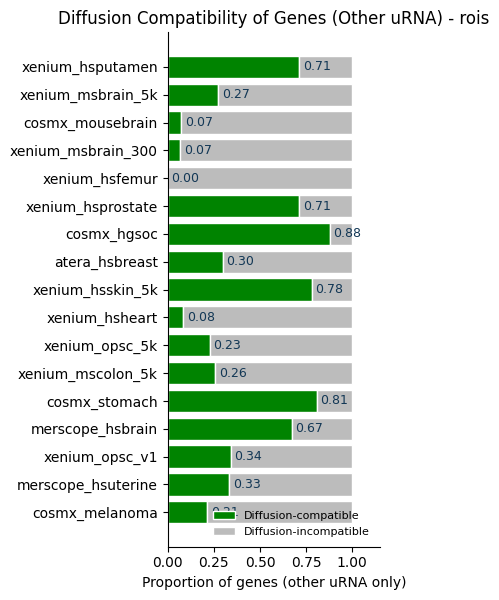

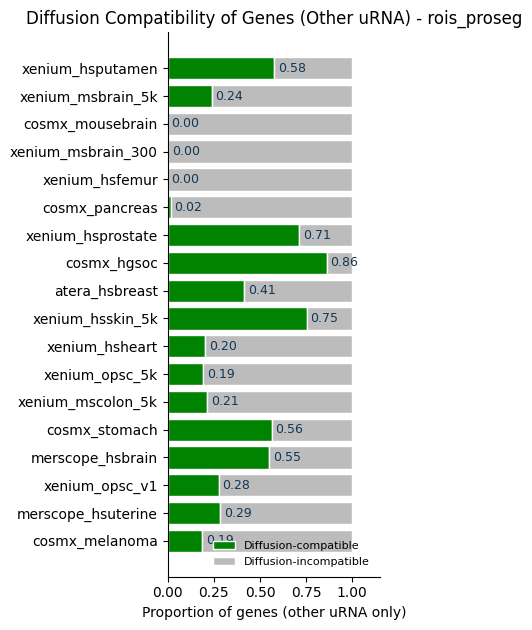

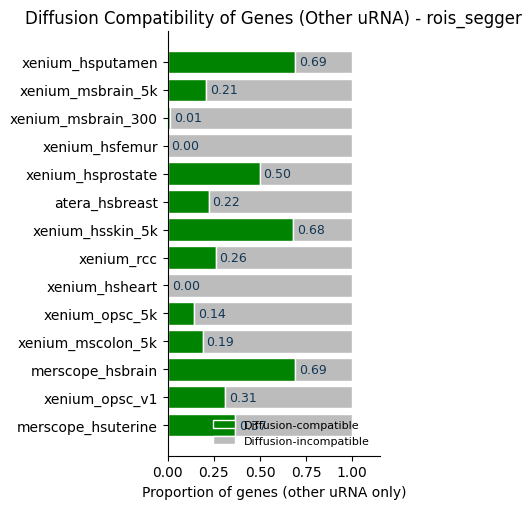

In [6]:
def plot_gene_compatibility(incompatible_values, xlabel, title, out_path):
    incompatible_values = incompatible_values.reindex(sample_order).dropna()
    compatible_values = 1 - incompatible_values

    fig, ax = plt.subplots(figsize=(4, 0.3 * len(incompatible_values) + 1))

    bars = ax.barh(compatible_values.index, compatible_values, color=diffusion_color, edgecolor="white", linewidth=1, label="Diffusion-compatible")
    ax.barh(incompatible_values.index, incompatible_values, left=compatible_values, color=other_color, edgecolor="white", linewidth=1, label="Diffusion-incompatible")

    for bar in bars:
        width = bar.get_width()
        ax.text(
            width + 0.02, bar.get_y() + bar.get_height() / 2,
            f"{width:.2f}", va="center", ha="left", color="#123755", fontsize=9,
        )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_xlim(0, 1.15)
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    ax.legend(loc="lower right", frameon=False, fontsize=8)
    plt.tight_layout()
    plt.savefig(out_path, bbox_inches="tight")
    plt.show()

for seg in segmentations:
    if seg not in other_rna_diffusion_df.index.get_level_values("segmentation"):
        continue
    values = other_rna_diffusion_df.xs(seg, level="segmentation")["proportion_of_other_genes_diffusion_incompatible"]
    plot_gene_compatibility(
        values,
        xlabel="Proportion of genes (other uRNA only)",
        title=f"Diffusion Compatibility of Genes (Other uRNA) - {seg}",
        out_path=os.path.join(saving_path, f"{seg}_barplot_genes_diffusion_compatibility.pdf"),
    )

## Context: how much of total RNA is "other" uRNA, and how much of that is diffusion-compatible

Same framing as the noise notebook's context plot: each bar's full length is the % of **all** transcripts in the sample that fall into the "other unassigned RNA" pool. The highlighted segment (from 0, for cross-sample comparability) is the sub-% attributable to genes whose spatial spread **is** compatible with isotropic diffusion; the gray remainder is everything else (diffusion-incompatible, plus genes that couldn't be diffusion-tested, plus control probes).

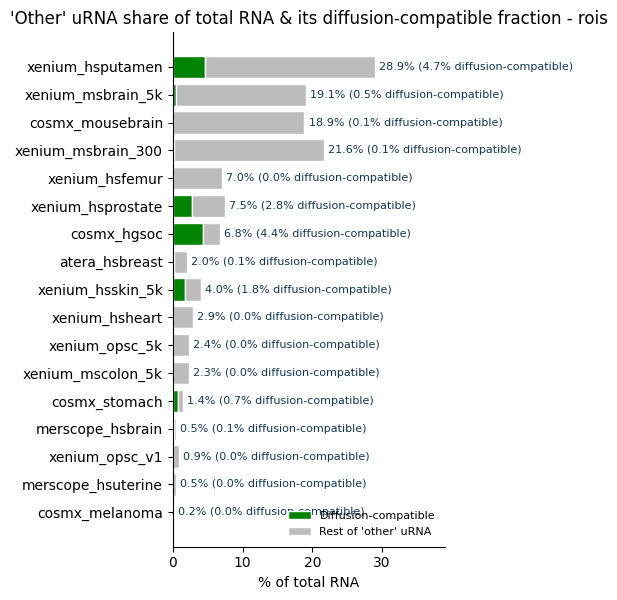

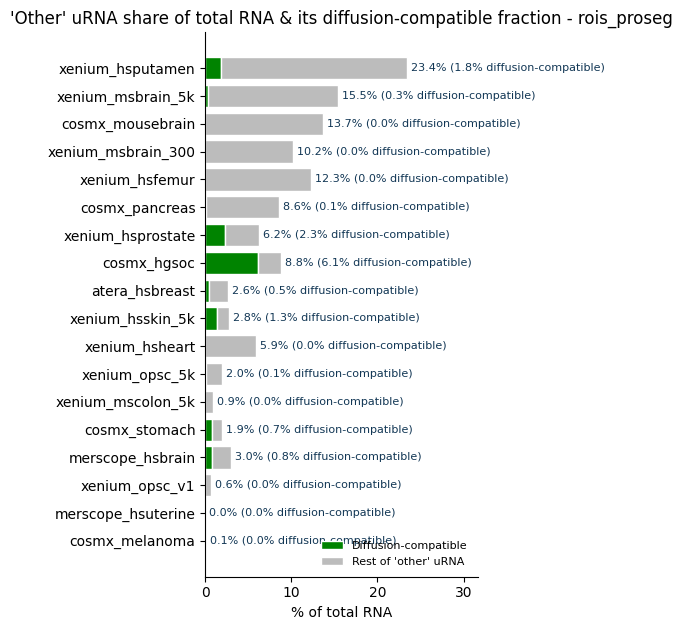

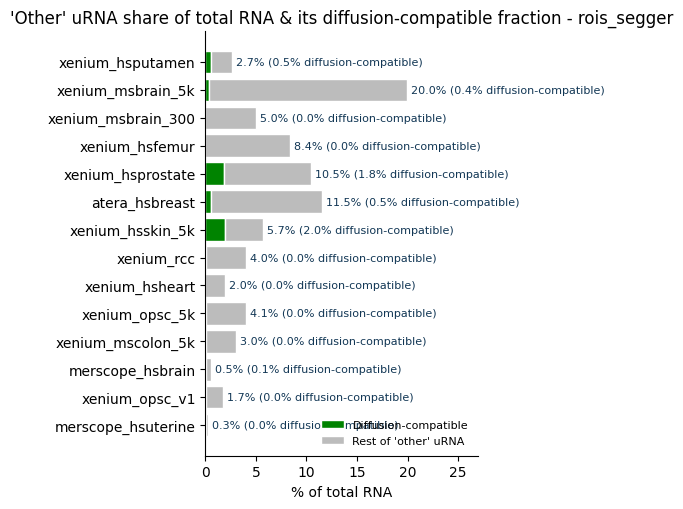

In [7]:
def plot_other_rna_context(df, value_col, color, xlabel, title, out_path, label_suffix):
    df = df.reindex(sample_order).dropna(subset=["proportion_of_total_rna_other"])

    total_pct = 100 * df["proportion_of_total_rna_other"]
    # value_col is a fraction *of the "other RNA" pool*, so scale it by total_pct
    # (not by 100 alone) to get its share of *total* RNA - matching the pattern in
    # 9_other_urna_noise_proportion.ipynb's context plot
    problem_pct = total_pct * df[value_col].fillna(0)
    rest_pct = total_pct - problem_pct

    fig, ax = plt.subplots(figsize=(5.5, 0.3 * len(df) + 1))

    ax.barh(df.index, problem_pct, color=color, edgecolor="white", linewidth=1, label=label_suffix)
    ax.barh(df.index, rest_pct, left=problem_pct, color=other_color, edgecolor="white", linewidth=1, label="Rest of 'other' uRNA")

    for y, (total, problem) in enumerate(zip(total_pct, problem_pct)):
        ax.text(
            total + total_pct.max() * 0.02, y,
            f"{total:.1f}% ({problem:.1f}% {label_suffix.lower()})",
            va="center", ha="left", color="#123755", fontsize=8,
        )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_xlim(0, total_pct.max() * 1.35)
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    ax.legend(loc="lower right", frameon=False, fontsize=8)
    plt.tight_layout()
    plt.savefig(out_path, bbox_inches="tight")
    plt.show()

for seg in segmentations:
    if seg not in other_rna_diffusion_df.index.get_level_values("segmentation"):
        continue
    df = other_rna_diffusion_df.xs(seg, level="segmentation")
    plot_other_rna_context(
        df,
        value_col="proportion_of_other_urna_diffusion_compatible",
        color=diffusion_color,
        xlabel="% of total RNA",
        title=f"'Other' uRNA share of total RNA & its diffusion-compatible fraction - {seg}",
        out_path=os.path.join(saving_path, f"{seg}_barplot_other_rna_context_and_diffusion.pdf"),
        label_suffix="Diffusion-compatible",
    )

## Alternative view: diffusion-compatible proportion compared across segmentation methods

The two plot types above repeat per segmentation method, which makes within-method patterns easy to read but not cross-method comparison. This view puts all 3 methods side by side per sample in a single figure instead.

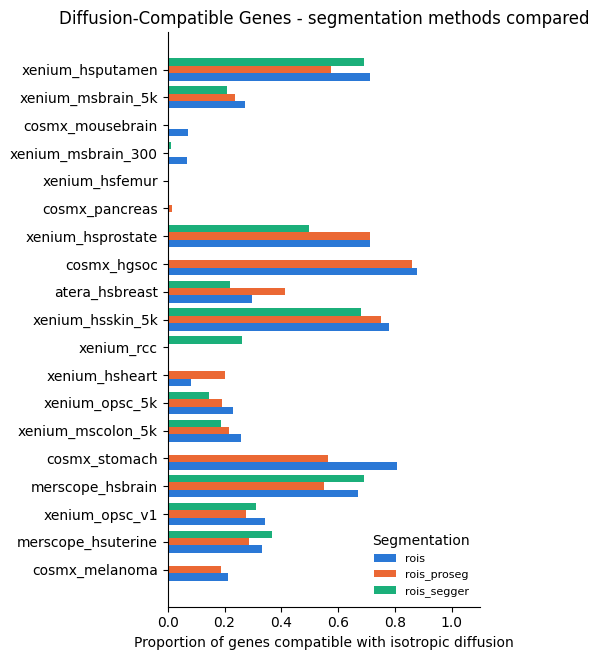

In [8]:
pivot = (
    (1 - other_rna_diffusion_df["proportion_of_other_genes_diffusion_incompatible"])
    .unstack("segmentation")
    .reindex(sample_order)
)

n_methods = len(segmentations)
bar_height = 0.8 / n_methods
fig, ax = plt.subplots(figsize=(5, 0.3 * len(pivot) + 1))

for i, seg in enumerate(segmentations):
    if seg not in pivot.columns:
        continue
    y_pos = np.arange(len(pivot)) - 0.4 + bar_height * (i + 0.5)
    ax.barh(y_pos, pivot[seg], height=bar_height, color=method_colors.get(seg, "#888888"), label=seg)

ax.set_yticks(np.arange(len(pivot)))
ax.set_yticklabels(pivot.index)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_xlim(0, 1.1)
ax.set_xlabel("Proportion of genes compatible with isotropic diffusion")
ax.set_title("Diffusion-Compatible Genes - segmentation methods compared")
ax.legend(loc="lower right", frameon=False, fontsize=8, title="Segmentation")
plt.tight_layout()
plt.savefig(os.path.join(saving_path, "barplot_genes_diffusion_compatible_by_method.pdf"), bbox_inches="tight")
plt.show()

## Joint analysis: noise x diffusion, in the context of total RNA

For each dataset, how much of the total RNA is "other" uRNA that is (a) both noise and diffusion-incompatible, (b) noise only, (c) diffusion-incompatible only, or (d) neither (clean signal, compatible with diffusion)? The light gray reference bar behind the stack is the full "other RNA" context (same total as the plots above); any gap between the colored stack and its tip is "other RNA" from control probes or genes that couldn't be diffusion-tested (too few transcripts).

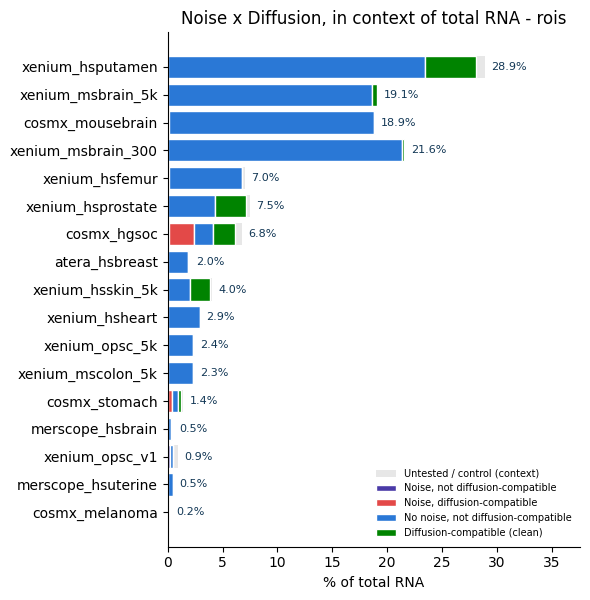

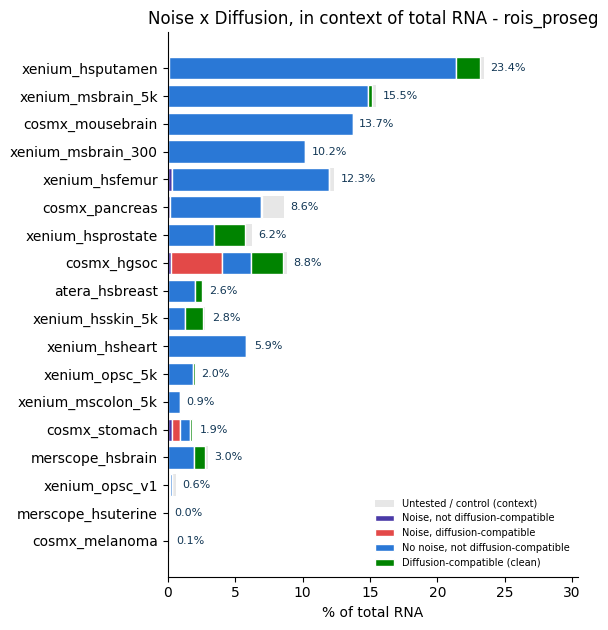

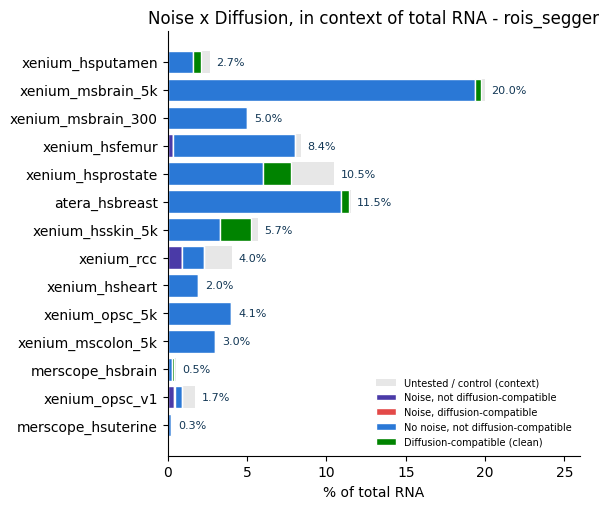

In [9]:
def plot_joint_quadrants(df, title, out_path):
    df = df.reindex(sample_order).dropna(subset=["proportion_of_total_rna_other"])

    total_pct = 100 * df["proportion_of_total_rna_other"]

    fig, ax = plt.subplots(figsize=(6, 0.3 * len(df) + 1))

    ax.barh(df.index, total_pct, color=other_color, alpha=0.35, label="Untested / control (context)")

    # Each urna_frac_* is a fraction *of the "other RNA" pool*, so scale by total_pct
    # (not by 100 alone) to plot it on the same "% of total RNA" scale as total_pct
    left = np.zeros(len(df))
    for label in quadrant_order:
        seg_pct = (total_pct * df[f"urna_frac_{label}"].fillna(0)).values
        ax.barh(df.index, seg_pct, left=left, color=quadrant_colors[label], edgecolor="white", linewidth=1, label=quadrant_labels[label])
        left += seg_pct

    for y, total in enumerate(total_pct):
        ax.text(total + total_pct.max() * 0.02, y, f"{total:.1f}%", va="center", ha="left", color="#123755", fontsize=8)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_xlim(0, total_pct.max() * 1.3)
    ax.set_xlabel("% of total RNA")
    ax.set_title(title)
    ax.legend(loc="lower right", frameon=False, fontsize=7)
    plt.tight_layout()
    plt.savefig(out_path, bbox_inches="tight")
    plt.show()

for seg in segmentations:
    if seg not in other_rna_diffusion_df.index.get_level_values("segmentation"):
        continue
    df = other_rna_diffusion_df.xs(seg, level="segmentation")
    plot_joint_quadrants(
        df,
        title=f"Noise x Diffusion, in context of total RNA - {seg}",
        out_path=os.path.join(saving_path, f"{seg}_barplot_noise_diffusion_joint_context.pdf"),
    )

## Compare diffusion-compatible proportion across segmentation methods

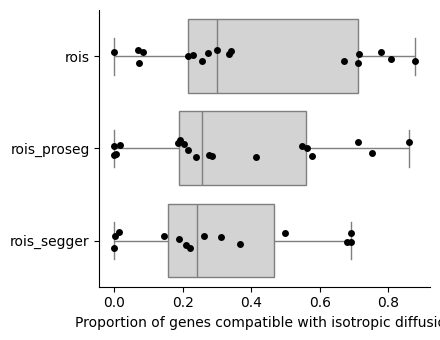

In [10]:
summary_df = other_rna_diffusion_df.reset_index()
summary_df["proportion_of_other_genes_diffusion_compatible"] = 1 - summary_df["proportion_of_other_genes_diffusion_incompatible"]

fig, ax = plt.subplots(figsize=(4.5, 3.5))
sns.boxplot(data=summary_df, x="proportion_of_other_genes_diffusion_compatible", y="segmentation", color="lightgrey", ax=ax)
sns.stripplot(data=summary_df, x="proportion_of_other_genes_diffusion_compatible", y="segmentation", color="black", s=5, ax=ax)
ax.set_xlabel("Proportion of genes compatible with isotropic diffusion")
ax.set_ylabel("")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig(os.path.join(saving_path, "boxplot_diffusion_compatible_by_segmentation.pdf"), bbox_inches="tight")
plt.show()